In [29]:
# copy code (Eda_clustering)
import datetime as dt
import numpy as np
import pandas as pd

import requests
import re

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import keras
import tensorflow as tf
from keras import layers
from keras.layers import RepeatVector
from keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard
from keras.layers import LSTM, Dropout, Dense
from keras.models import Sequential, Model, load_model
from keras.layers import Input, Dense, Activation, Flatten, Dropout
from keras.layers import SimpleRNN, GRU
from keras.utils import to_categorical
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Input

from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

import pickle 
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense

import prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation
from prophet.diagnostics import performance_metrics
from prophet.plot import add_changepoints_to_plot
from prophet.plot import plot_cross_validation_metric
from prophet.plot import plot_plotly
from prophet.serialize import model_to_json
import plotly.graph_objs as go

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp:  # Reads File
        return pickle.load(inp)

In [30]:
### Visualization 2020 to 2023

df = pd.read_csv("./CSV data/GT/GT_final.csv")
df.head()

,b210,b055,b103,b166,b002,b084
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,34.004465,0.5,73.468982,16.341133,25.617303
2,NaN,29.393972,0.5,83.152133,14.102179,24.518448
3,NaN,25.179674,0.0,81.051718,14.446331,24.286499
4,NaN,29.275846,0.0,74.796495,14.196912,24.098361


In [31]:
start_date = '2020-01-01 00:00:00'
num_rows = len(df)
date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')

df['date'] = date_range
df.to_csv("./CSV data/GT/GT_final_date.csv", index = False)

/var/folders/tj/9vhjqp2n63ng9609fgfkf_dc0000gn/T/ipykernel_54599/1736249241.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')


In [32]:
df.head()

,b210,b055,b103,b166,b002,b084,date
0,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-01 00:00:00
1,NaN,34.004465,0.5,73.468982,16.341133,25.617303,2020-01-01 01:00:00
2,NaN,29.393972,0.5,83.152133,14.102179,24.518448,2020-01-01 02:00:00
3,NaN,25.179674,0.0,81.051718,14.446331,24.286499,2020-01-01 03:00:00
4,NaN,29.275846,0.0,74.796495,14.196912,24.098361,2020-01-01 04:00:00


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


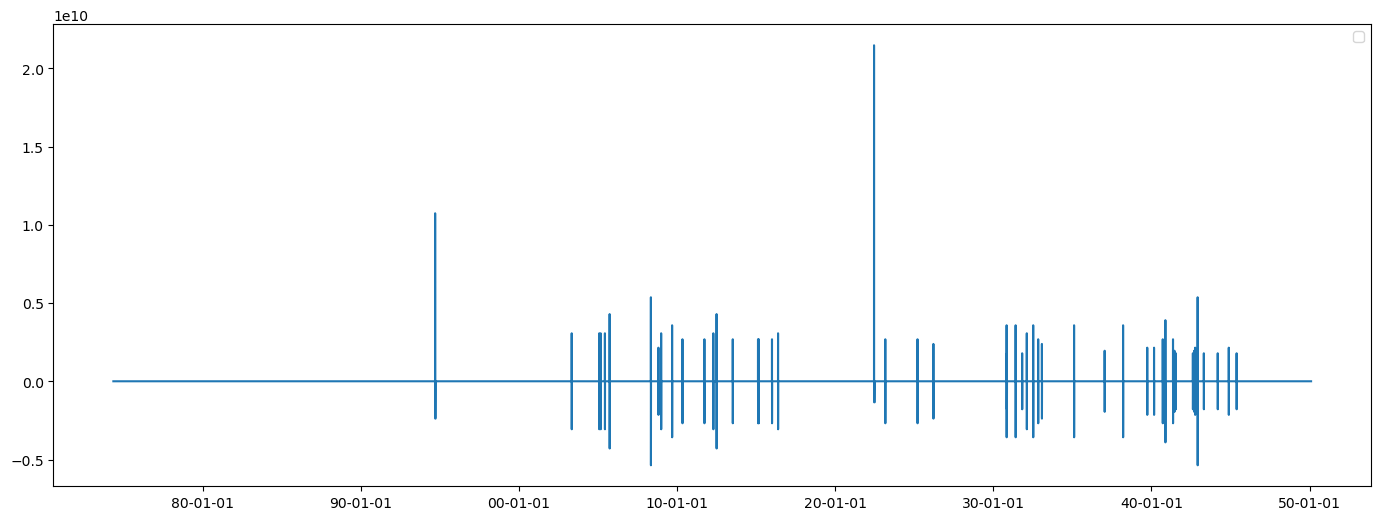

In [33]:
# visualize data 1

plt.figure(figsize=(17, 6))
plt.plot(df.index, df['b210'])

days = mdates.AutoDateLocator()
plt.gca().xaxis.set_major_locator(days)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))

plt.legend()
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


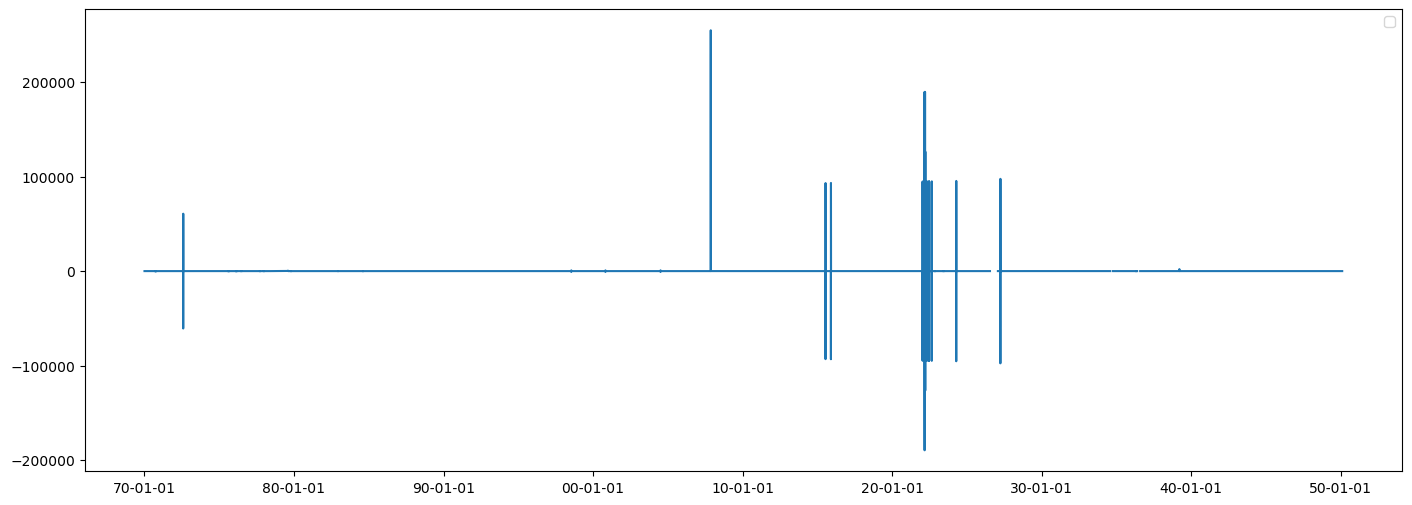

In [34]:
plt.figure(figsize=(17, 6))
plt.plot(df.index, df['b103'])

days = mdates.AutoDateLocator()
plt.gca().xaxis.set_major_locator(days)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))

plt.legend()
plt.show()

In [35]:
### spike 처리 

date = df['date']
df = df[df.iloc[:, :-1] < 300]
df = df[df.iloc[:, :-1] > -300]
df['date'] = date

In [36]:
df.head()

,b210,b055,b103,b166,b002,b084,date
0,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-01 00:00:00
1,NaN,34.004465,0.5,73.468982,16.341133,25.617303,2020-01-01 01:00:00
2,NaN,29.393972,0.5,83.152133,14.102179,24.518448,2020-01-01 02:00:00
3,NaN,25.179674,0.0,81.051718,14.446331,24.286499,2020-01-01 03:00:00
4,NaN,29.275846,0.0,74.796495,14.196912,24.098361,2020-01-01 04:00:00


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


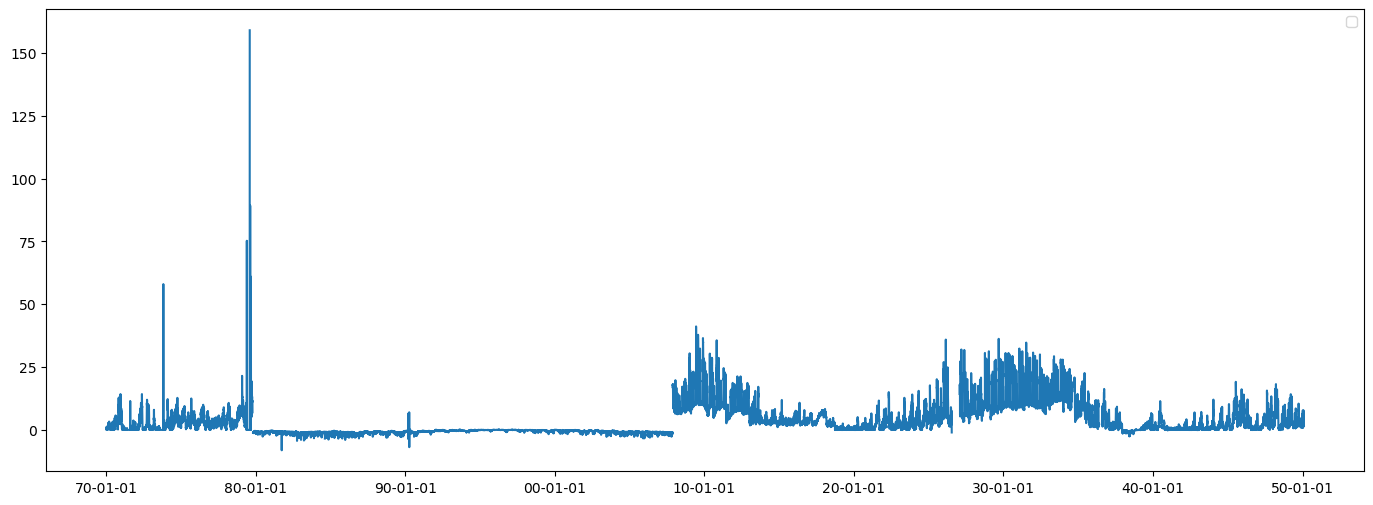

In [37]:
plt.figure(figsize=(17, 6))
plt.plot(df.index, df['b103'])

days = mdates.AutoDateLocator()
plt.gca().xaxis.set_major_locator(days)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))

plt.legend()
plt.show()

### Neural ODE

In [40]:
import torch
import torch.nn as nn
from torchdiffeq import odeint
import numpy as np
import pandas as pd

class NeuralODE(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)

    def forward(self, t, y):
        return self.fc2(torch.relu(self.fc1(y)))

def extract_periodic_features(data):
    # Fourier 변환을 사용하여 주기 정보 추출
    fft_result = np.fft.fft(data.to_numpy())
    periodic_features = np.abs(fft_result[:len(data)//2])  # 주기 성분만 사용
    return torch.tensor(periodic_features, dtype=torch.float32)

def detect_spikes_with_periodicity(df, column_names, threshold):
    # 데이터프레임에서 특정 열 선택
    data = df[column_names].dropna()  # 결측값 제거
    data_tensor = torch.tensor(data.values, dtype=torch.float32)  # 텐서로 변환

    # 주기 정보 추출
    periodic_features = []
    for col in column_names:
        periodic_feature = extract_periodic_features(data[col])
        periodic_features.append(periodic_feature)
    
    periodic_features = torch.cat(periodic_features)  # 모든 주기 성분을 하나의 텐서로 결합

    # Neural ODE 모델 초기화
    model = NeuralODE(input_dim=data_tensor.shape[1] + periodic_features.shape[0], hidden_dim=64)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    # ODE 솔버를 사용하여 데이터 처리
    t = torch.linspace(0, 1, data_tensor.size(0))
    y0 = torch.cat((data_tensor[0], periodic_features)).unsqueeze(0)  # 초기값 설정
    solution = odeint(model, y0, t)

    # 스파이크 감지
    spikes = (solution.squeeze() > threshold).float()
    return spikes, data_tensor

# 스파이크 감지 실행
threshold = 2  # 예시 임계값
spikes, data_tensor = detect_spikes_with_periodicity(df, ['b055', 'b103', 'b166', 'b002', 'b084'], threshold)
print(spikes)

tensor([[1., 0., 1.,  ..., 1., 1., 1.],
        [1., 0., 1.,  ..., 1., 1., 1.],
        [1., 0., 1.,  ..., 1., 1., 1.],
        ...,
        [0., 0., 1.,  ..., 0., 1., 1.],
        [0., 0., 1.,  ..., 0., 1., 1.],
        [0., 0., 1.,  ..., 0., 1., 1.]])


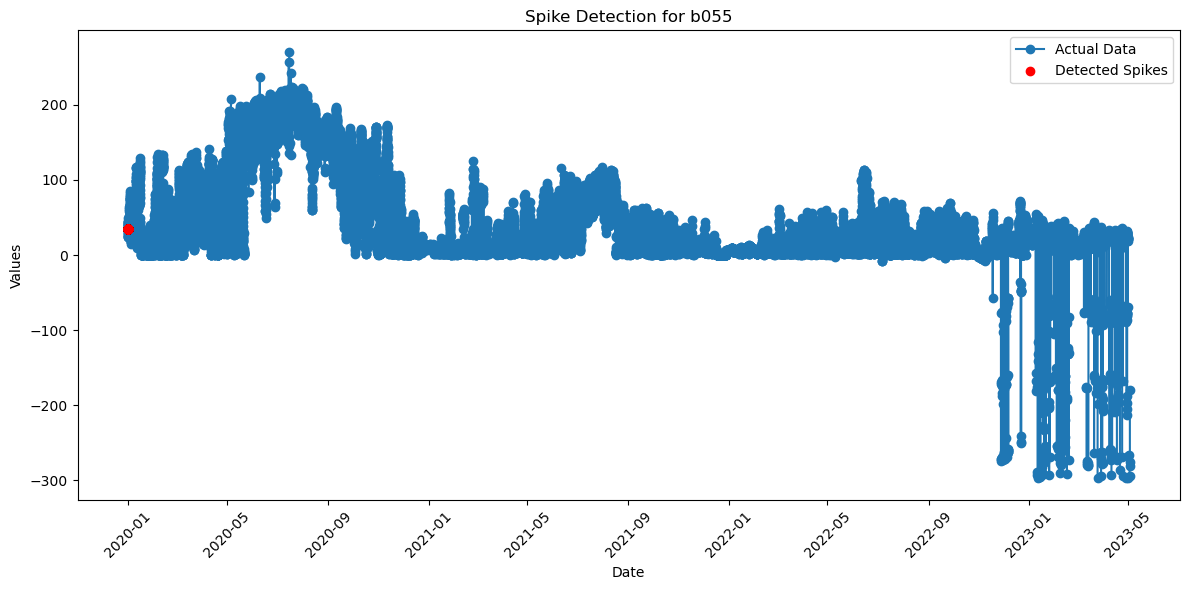

In [42]:
# 결과 시각화
def plot_spikes_for_single_variable(df, col, spikes):
    plt.figure(figsize=(12, 6))
    plt.plot(df['date'], df[col], label='Actual Data', marker='o')
    
    # 스파이크 감지 결과를 1차원으로 변환
    spike_indices = spikes.squeeze().bool() 
    # 스파이크 인덱스에 맞춰 데이터 필터링
    if spike_indices.ndim > 1:  # 2차원인 경우
        spike_indices = spike_indices[:, 0]  # 첫 번째 열만 사용

    plt.scatter(df['date'].iloc[spike_indices], df[col].iloc[spike_indices], color='red', label='Detected Spikes', zorder=5)
    
    plt.title(f'Spike Detection for {col}')
    plt.xlabel('Date')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

# 예시로 'b055' 변수에 대해 시각화
plot_spikes_for_single_variable(df, 'b055', spikes)

Detected Spikes:
[[1. 0. 1. ... 1. 1. 1.]
 [1. 0. 1. ... 1. 1. 1.]
 [1. 0. 1. ... 1. 1. 1.]
 ...
 [1. 1. 0. ... 1. 1. 1.]
 [1. 1. 0. ... 1. 1. 1.]
 [1. 1. 0. ... 1. 1. 1.]]


IndexError: Boolean index has wrong length: 24921 instead of 29256

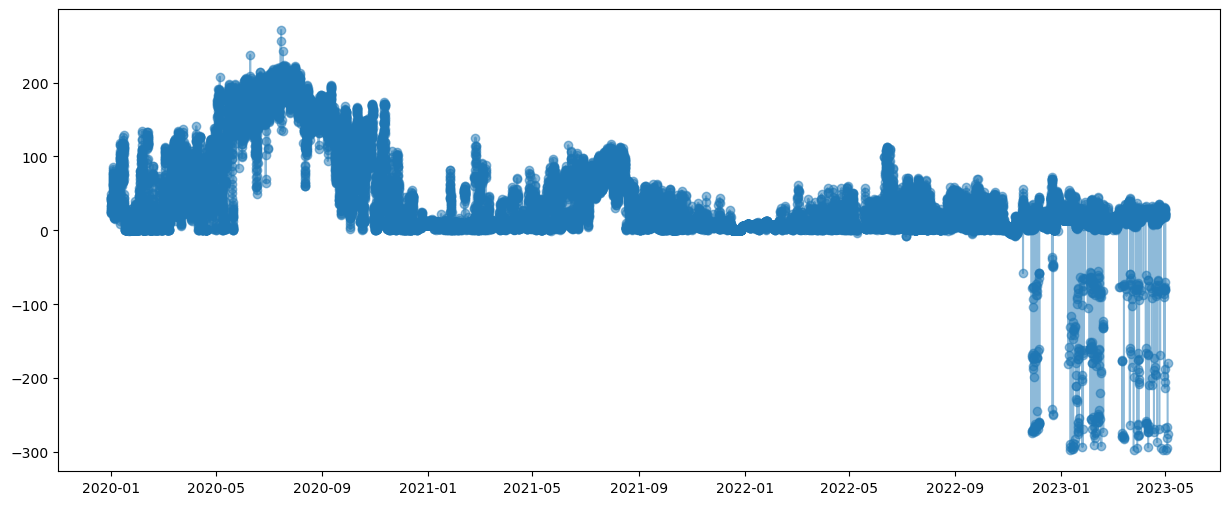

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report
import torch
import torch.nn as nn
from torchdiffeq import odeint

# Neural ODE 모델 정의
class NeuralODE(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)

    def forward(self, t, y):
        return self.fc2(torch.relu(self.fc1(y)))

# 주기적 특성 추출 함수
def extract_periodic_features(data):
    # Fourier 변환을 사용하여 주기 정보 추출
    fft_result = np.fft.fft(data.to_numpy())
    periodic_features = np.abs(fft_result[:len(data)//2])  
    return torch.tensor(periodic_features, dtype=torch.float32)

# 스파이크 감지 함수
def detect_spikes_with_periodicity(df, column_names, threshold):
    data = df[column_names].dropna()
    data_tensor = torch.tensor(data.values, dtype=torch.float32) 

    # 주기 정보 추출
    periodic_features = []
    for col in column_names:
        periodic_feature = extract_periodic_features(data[col])
        periodic_features.append(periodic_feature)
    
    periodic_features = torch.cat(periodic_features)  # 모든 주기 성분을 하나의 텐서로 결합

    # Neural ODE 모델 초기화
    model = NeuralODE(input_dim=data_tensor.shape[1] + periodic_features.shape[0], hidden_dim=64)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    # ODE 솔버를 사용하여 데이터 처리
    t = torch.linspace(0, 1, data_tensor.size(0))
    y0 = torch.cat((data_tensor[0], periodic_features)).unsqueeze(0) 
    solution = odeint(model, y0, t)

    # 스파이크 감지
    spikes = (solution.squeeze() > threshold).float()
    spikes = spikes.squeeze().numpy() 

    return spikes, data_tensor

# 스파이크 감지 실행
threshold = 2  
spikes, data_tensor = detect_spikes_with_periodicity(df, ['b055', 'b103', 'b166', 'b002', 'b084'], threshold)

# Neural ODE 결과 출력
print("Detected Spikes:")
print(spikes)

# One-Class SVM을 사용한 이상치 감지
oc_svm = OneClassSVM(kernel='rbf', gamma='auto').fit(data_tensor.detach().numpy())
oc_svm_predictions = oc_svm.predict(data_tensor.detach().numpy())

# 이상치 결과를 0과 1로 변환 (1: 정상, -1: 이상치)
oc_svm_anomalies = (oc_svm_predictions == -1).astype(float)

# 성능 평가를 위한 실제 라벨 생성 (예시로 스파이크가 있는 인덱스를 1로 설정)
true_labels = np.zeros(data_tensor.shape[0])
true_labels[np.random.choice(data_tensor.shape[0], size=int(data_tensor.shape[0] * 0.1), replace=False)] = 1  

# 성능 평가
# print("Neural ODE Performance:")
# print(classification_report(true_labels, spikes.numpy().astype(int)))  
 
# print("One-Class SVM Performance:")
# print(classification_report(true_labels, oc_svm_anomalies))

# Neural ODE 결과를 1차원 배열로 변환
spikes = spikes.squeeze()

# 결과 시각화
plt.figure(figsize=(15, 6))
plt.plot(df['date'], df['b055'], label='b055', marker='o', alpha=0.5)

# Neural ODE 스파이크 시각화
plt.scatter(df['date'][spikes == 1], df['b055'][spikes == 1], color='red', label='Neural ODE Spikes', zorder=5)


In [58]:
# One-Class SVM을 사용한 이상치 감지
oc_svm = OneClassSVM(kernel='rbf', gamma='auto').fit(data_tensor.detach().numpy())
oc_svm_predictions = oc_svm.predict(data_tensor.detach().numpy())

# 이상치 결과를 0과 1로 변환 (1: 정상, -1: 이상치)
oc_svm_anomalies = (oc_svm_predictions == -1).astype(float)

# 결과 시각화
plt.figure(figsize=(15, 6))
plt.plot(df['date'], df['b055'], label='b055', marker='o', alpha=0.5)

# Neural ODE 스파이크 시각화
plt.scatter(df['date'][spikes == 1], df['b055'][spikes == 1], color='red', label='Neural ODE Spikes', zorder=5)

# One-Class SVM 이상치 시각화
# oc_svm_anomalies의 길이를 df의 길이에 맞추기 위해 iloc 사용
plt.scatter(df['date'].iloc[:len(oc_svm_anomalies)][oc_svm_anomalies == 1], 
            df['b055'].iloc[:len(oc_svm_anomalies)][oc_svm_anomalies == 1], 
            color='orange', label='One-Class SVM Anomalies', zorder=5)

plt.title('Spike Detection and Anomaly Detection')
plt.xlabel('Date')
plt.ylabel('Values')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
import torch
import torch.nn as nn
import torchdiffeq  # Neural ODE library
import matplotlib.pyplot as plt

class ODEFunc(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODEFunc, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)
    
    def forward(self, t, y):
        y = torch.relu(self.fc1(y))
        return self.fc2(y)

class NeuralODEModel(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = ODEFunc(input_dim, hidden_dim)
    
    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)


# Training loop for Neural ODE
def train_ode_model(model, data, time, epochs=500, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()

        # Initial condition (y0) is the first observation
        y0 = data[0].unsqueeze(0)  # Ensure y0 is of shape [1, num_features]

        # Forward pass through the ODE model
        pred = model(y0, time)

        # Compute loss (reconstruction error)
        huber_loss = nn.HuberLoss()
        loss = huber_loss(pred, data.unsqueeze(0))  # Ensure data has proper shape [1, num_features, num_timesteps]

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

# Anomaly detection: Calculate reconstruction error as anomaly score
def detect_anomalies(model, data, time, threshold=0.1):
    y0 = data[0]
    pred = model(y0, time)
    reconstruction_error = torch.mean((pred - data) ** 2, dim=1)
    anomalies = reconstruction_error > threshold
    return anomalies, reconstruction_error

def plot_predictions(time, true_data, predicted_data):
    num_vars = true_data.shape[1]
    
    plt.figure(figsize=(12, 6 * num_vars))
    for i in range(num_vars):
        plt.subplot(num_vars, 1, i+1)
        plt.plot(time.numpy(), true_data[:, i].numpy(), label='True Data')
        plt.plot(time.numpy(), predicted_data[:, i].detach().numpy(), label='Predicted Data', linestyle='--')
        plt.xlabel('Time (hours)')
        plt.ylabel(f'Variable {i+1}')
        plt.legend()
    plt.tight_layout()
    plt.show()

In [21]:
from fancyimpute import IterativeImputer

# Initialize and train the model
csv_file_path = './CSV data/GT/GT_final_date.csv'  
df = pd.read_csv(csv_file_path)

# Convert 'date' to numerical format (e.g., hours since start)
df['date'] = pd.to_datetime(df['date'])
df['date_numeric'] = (df['date'] - df['date'].min()).dt.total_seconds() / 3600

# Include 'date_numeric' in the imputation process
df2 = df.drop(['date'], axis=1)
data = df2.values

# Initialize MICE imputer
mice_imputer = IterativeImputer()

# Perform imputation
imputed_data = mice_imputer.fit_transform(data)

# Convert imputed data back to DataFrame
imputed_df = pd.DataFrame(imputed_data, columns=df2.columns)
imputed_df['date'] = df['date'] 
imputed_df['date_numeric'] = (imputed_df['date'] - imputed_df['date'].min()).dt.total_seconds() / 3600

In [23]:
# Ensure time steps are unique and sufficiently spaced
time = torch.tensor(imputed_df['date_numeric'].values, dtype=torch.float32)
time_diff = time.diff()

# Adjust time steps if any are zero or too small
min_time_step = 1e-2  # Set a minimum allowed time step
time_diff = torch.where(time_diff == 0, min_time_step, time_diff)  # Replace zero differences

# Recalculate time from the adjusted differences
time_adjusted = torch.cumsum(time_diff, dim=0)
time_adjusted = torch.cat((torch.tensor([time[0]]), time_adjusted))  # Include the initial time

# Normalize time between 0 and 1
time_normalized = (time_adjusted - time_adjusted.min()) / (time_adjusted.max() - time_adjusted.min())

# Convert imputed data to PyTorch tensor
data = torch.tensor(imputed_df.drop(['date', 'date_numeric'], axis=1).values, dtype=torch.float32)

In [24]:
# Initialize and train the model
input_dim = data.shape[1]  # Number of features in the data
hidden_dim = 50  # Hidden dimension size

ode_model = NeuralODEModel(input_dim, hidden_dim)
train_ode_model(ode_model, data, time_normalized)

# Predict and plot
y0 = data[0].unsqueeze(0)  # Initial condition for prediction
predicted = ode_model(y0, time_normalized)

/opt/anaconda3/envs/career/lib/python3.11/site-packages/torch/nn/modules/loss.py:999: UserWarning: Using a target size (torch.Size([1, 29256, 6])) that is different to the input size (torch.Size([29256, 1, 6])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.huber_loss(input, target, reduction=self.reduction, delta=self.delta)


Epoch 0, Loss: 6429071.0
Epoch 10, Loss: 6169923.5
Epoch 20, Loss: 6042227.5
Epoch 30, Loss: 5962905.0
Epoch 40, Loss: 5904445.5
Epoch 50, Loss: 5860411.5
Epoch 60, Loss: 5819851.0
Epoch 70, Loss: 5778532.0
Epoch 80, Loss: 5736408.0
Epoch 90, Loss: 5696644.0
Epoch 100, Loss: 5656487.0
Epoch 110, Loss: 5617336.5
Epoch 120, Loss: 5577563.0
Epoch 130, Loss: 5539727.5
Epoch 140, Loss: 5502061.5
Epoch 150, Loss: 5462732.0
Epoch 160, Loss: 5426233.0
Epoch 170, Loss: 5389188.0
Epoch 180, Loss: 5354967.5
Epoch 190, Loss: 5317069.5
Epoch 200, Loss: 5283030.5
Epoch 210, Loss: 5247810.5
Epoch 220, Loss: 5215267.0
Epoch 230, Loss: 5182472.0
Epoch 240, Loss: 5152455.0
Epoch 250, Loss: 5120677.0
Epoch 260, Loss: 5091159.0
Epoch 270, Loss: 5063383.5
Epoch 280, Loss: 5035992.5
Epoch 290, Loss: 5009796.5
Epoch 300, Loss: 4984998.0
Epoch 310, Loss: 4959976.5
Epoch 320, Loss: 4936718.0
Epoch 330, Loss: 4913600.5
Epoch 340, Loss: 4891809.0
Epoch 350, Loss: 4870829.5
Epoch 360, Loss: 4850446.0
Epoch 370, L

In [27]:
import torch
import torchdiffeq
from nflows import transforms, distributions, flows

class FlowLayer(torch.nn.Module):
    def __init__(self, input_dim):
        super(FlowLayer, self).__init__()
        self.base_dist = distributions.StandardNormal([input_dim])
        self.transform = transforms.CompositeTransform([
            transforms.AffineCoupling(input_dim=input_dim // 2),
            transforms.ActNorm(input_dim),
        ])
        self.flow = flows.Flow(self.transform, self.base_dist)

    def forward(self, x):
        # Forward pass through normalizing flow
        z, log_det = self.flow._transform.forward(x)
        return z, log_det

class NeuralODEModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = torch.nn.Sequential(
            torch.nn.Linear(input_dim, hidden_dim),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)

class CombinedModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(CombinedModel, self).__init__()
        self.flow_layer = FlowLayer(input_dim)
        self.ode_layer = NeuralODEModel(input_dim, hidden_dim)

    def forward(self, x, t):
        # Forward pass through normalizing flow first
        z, log_det = self.flow_layer(x)
        # Then pass through the neural ODE
        z_ode = self.ode_layer(z, t)
        return z_ode, log_det

# Loss function that combines reconstruction and flow log-likelihood
def loss_function(pred, true, log_det, weight=1.0):
    # Reconstruction loss (e.g., MSE)
    reconstruction_loss = torch.nn.functional.mse_loss(pred, true)
    # Flow log-likelihood loss
    flow_loss = -log_det.mean()
    return reconstruction_loss + weight * flow_loss

# Example training loop
def train_combined_model(model, data, time, epochs=100, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        # Initial condition for ODE
        y0 = data[0].unsqueeze(0)
        pred, log_det = model(y0, time)

        # Compute loss
        loss = loss_function(pred, data, log_det)

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

### ID-CNN & LSTM-AE

In [21]:
reconstructed_data.index = reconstructed_data['ds']
reconstructed_data = reconstructed_data.drop(['ds'], axis = 1)

In [23]:
prof1.index = prof1['ds']
prof1 = prof1.drop(['Date/Time', 'ds'], axis = 1)

In [25]:
# Input
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 
num_samples = len(signal_train) 

# 추세와 계절성 데이터 추출 (이전에 설명한 방법 사용)
input_layer = Input(shape=(num_samples, 1))
conv1 = Conv1D(filters=16, kernel_size=5, activation='relu')(input_layer)
maxpool1 = MaxPooling1D(pool_size=2)(conv1)
conv2 = Conv1D(filters=32, kernel_size=5, activation='relu')(maxpool1)
maxpool2 = MaxPooling1D(pool_size=2)(conv2)
flatten = Flatten()(maxpool2)

# 추세 및 계절성 패턴을 추출하는 모델 생성
model = keras.Model(inputs = input_layer, outputs = flatten)
model.compile(optimizer = 'adam', loss = 'mse')

train_data = signal_train.reshape(1, len(signal_train), 1)
model.fit(train_data, train_data, epochs=50, batch_size=16, validation_data=(train_data, train_data))
val_data = signal_valid.reshape(1, num_samples - len(signal_valid), 1)
predictions = model.predict(val_data)

# LSTM Autoencoder 모델 정의
encoding_dim = 64
timesteps = num_samples
features = 1

Epoch 1/50


ValueError: in user code:

    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1377, in train_function  *
        return step_function(self, iterator)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1360, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1349, in run_step  **
        outputs = model.train_step(data)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1127, in train_step
        loss = self.compute_loss(x, y, y_pred, sample_weight)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1185, in compute_loss
        return self.compiled_loss(
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/si

In [26]:
num_series = 1
epochs = 10
window_size = 10

# 1D CNN (extract trend & seasonality)
def extract_trend_seasonality(series, window_size):
    model = Sequential([
        Conv1D(filters = 32, kernel_size = window_size, activation = 'relu', input_shape = (None, 1)),
        MaxPooling1D(pool_size = 2),
        LSTM(50, activation = 'relu'),
        Dense(1)
    ])

    model.compile(optimizer = 'adam', loss = 'mse')
    series = np.array(series).reshape((num_series, -1, 1))
    model.fit(series, series, epochs = epochs)

    # 추출된 트렌드 및 시즌얼리 데이터
    trend_seasonality = model.predict(series)
    return trend_seasonality

# LSTM을 통한 훈련
def train_lstm_on_trend_seasonality(trend_seasonality):
    model = Sequential([
        LSTM(50, activation='relu', input_shape = (None, 1), return_sequences = True),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mae')
    trend_seasonality = np.array(trend_seasonality).reshape((num_series, -1, 1))
    model.fit(trend_seasonality, trend_seasonality, epochs = epochs)

    return model

# 트렌드 및 시즌얼리 데이터 추출
trend_seasonality = extract_trend_seasonality(signal_train, window_size)

# LSTM을 통한 훈련
lstm_model = train_lstm_on_trend_seasonality(trend_seasonality)


Epoch 1/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 2/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 3/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 4/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 5/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 6/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 7/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 8/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 9/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 10/10
1/1 [==============================] - 0s 436ms/step
Epoch 1/10
1/1 [==============================] - 1s 607ms/step - loss: 0.0015
Epoch 2/10
1/1 [==============================] - 0s 3ms/step - loss: 6.6912e-06
Epoch 3/10
1/1 [==============================] - 0s 3ms/step - loss: 0.0014
Epoch 4/10
1/1

In [88]:
# 예측 및 시각화
signal_test[np.isnan(signal_test)] = 0
test_series = signal_test
test_series = np.array(test_series).reshape((-1, 1))

predicted_trend_seasonality = lstm_model.predict(test_series.reshape((1, -1, 1)))

1/1 [==============================] - 1s 662ms/step


In [84]:
predicted_trend_seasonality

array([[0.00475079]], dtype=float32)

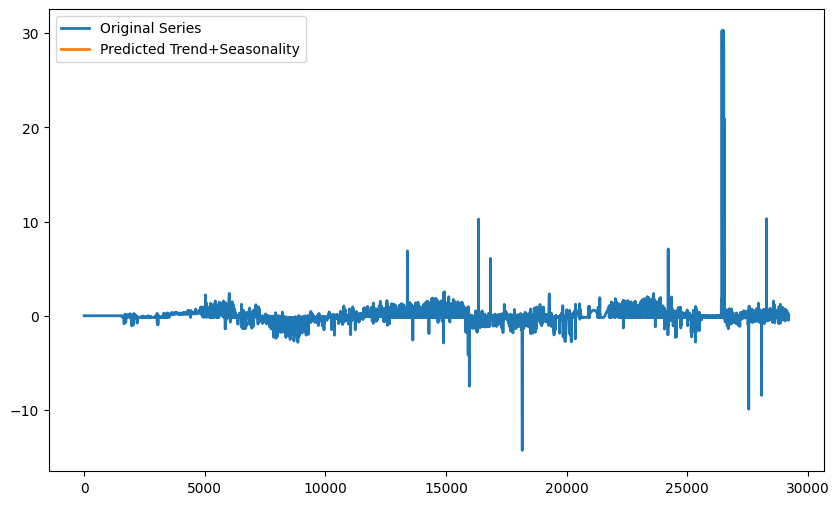

In [83]:
plt.figure(figsize=(10, 6))
plt.plot(test_series[:, :], label='Original Series', linewidth=2)
plt.plot(predicted_trend_seasonality[:, :], label='Predicted Trend+Seasonality', linewidth=2)
plt.legend()
plt.show()

In [61]:
predicted_trend_seasonality = lstm_model.predict(test_series)

1/1 [==============================] - 1s 699ms/step


### LSTM-AE with reconstructed_data as normal

In [58]:
reconstructed_data.index = pd.to_datetime(reconstructed_data['ds'])
reconstructed_data = reconstructed_data.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/1548268338.py:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [59]:
# orignal data
prof1.index = pd.to_datetime(prof1['ds'])
prof1 = prof1.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/2715252278.py:3: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [60]:
### split data
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 

# set window length
window_length = 12 * 2

train_windows = []

for window_start in range(0, len(signal_train) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_train[window_range])
    train_windows.append(window)
    
# shape of training set
x_train = np.array(train_windows)
x_train.shape

valid_windows = []
for window_start in range(0, len(signal_valid) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_valid[window_range])
    valid_windows.append(window)
    
# shape of validation set
x_valid = np.array(valid_windows)
x_valid.shape

test_windows = []

for window_start in range(0, len(signal_test) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_test[window_range])
    test_windows.append(window)

In [79]:
### LSTM Auto-Encoder Model
# optimizer list: adam, adamW, adadelta, adagrad, adamax, nadam

input_length = window_length
input_dim = 1 # number of variable
hidden_dim = 5
batch_size = 64
epochs = 100
opt = keras.optimizers.Adam(learning_rate=0.0005)

def model():
    m = Sequential()
    m.add(LSTM(units=4 * hidden_dim, activation='relu', input_shape=(input_length, input_dim), return_sequences=True))
    m.add(Dropout(rate=0.3))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=4 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(Dense(1))
    return m

# https://gooopy.tistory.com/90
m = model()
m.compile(loss='mse', optimizer=opt) # adam to rmsprop
m.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 24, 20)            1760      
                                                                 
 dropout_6 (Dropout)         (None, 24, 20)            0         
                                                                 
 lstm_7 (LSTM)               (None, 24, 10)            1240      
                                                                 
 dropout_7 (Dropout)         (None, 24, 10)            0         
                                                                 
 lstm_8 (LSTM)               (None, 24, 5)             320       
                                                                 
 dropout_8 (Dropout)         (None, 24, 5)             0         
                                                                 
 lstm_9 (LSTM)               (None, 24, 5)            

In [80]:
checkpointer = ModelCheckpoint(filepath = "lstm.autoencoder.weights.best.hdf5", verbose = 1, save_best_only = True)
earlystopper = EarlyStopping(monitor = 'val_loss', patience = 10, verbose = 0)
tbCallBack = TensorBoard(log_dir = './lstm.autoencoder.tb.graph', histogram_freq = 0, write_graph = True, write_images = True)

In [81]:
history = m.fit(x_train, x_train, batch_size = batch_size, epochs = epochs, validation_data = (x_valid, x_valid), 
                callbacks = [checkpointer, earlystopper, tbCallBack], verbose = 0).history


Epoch 1: val_loss improved from inf to 0.00350, saving model to lstm.autoencoder.weights.best.hdf5

Epoch 2: val_loss did not improve from 0.00350

Epoch 3: val_loss did not improve from 0.00350

Epoch 4: val_loss did not improve from 0.00350

Epoch 5: val_loss did not improve from 0.00350

Epoch 6: val_loss did not improve from 0.00350

Epoch 7: val_loss did not improve from 0.00350

Epoch 8: val_loss did not improve from 0.00350

Epoch 9: val_loss did not improve from 0.00350

Epoch 10: val_loss did not improve from 0.00350

Epoch 11: val_loss did not improve from 0.00350


In [82]:
pred_x_valid = m.predict(x_valid)

67/67 [==============================] - 1s 5ms/step


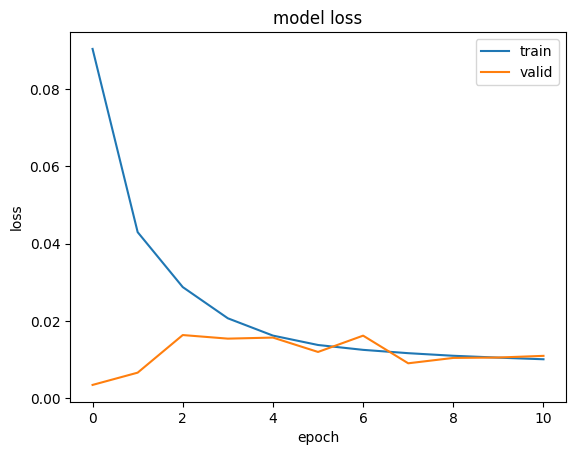

In [83]:
# summarize history for loss
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='best')
plt.show()

In [84]:
x_test = np.array(test_windows)
pred_x_test = m.predict(x_test)

913/913 [==============================] - 5s 5ms/step


In [85]:
# calculate error score
all_errors_valid = pd.Series(np.squeeze((x_valid.shape[:-1]) - pred_x_valid.reshape(pred_x_valid.shape[:-1])[:,:]).flatten())
all_errors_test = pd.Series(np.squeeze((x_test.shape[:-1]) - pred_x_test.reshape(pred_x_test.shape[:-1])[:,:]).flatten())

In [86]:
# calculate error score (window)
def sum_abs_errors_window(errors_in_window):
    return np.sum(np.abs(errors_in_window))

errors_test_per_window = np.squeeze(x_test.shape[:-1] -  pred_x_test.reshape(pred_x_test.shape[:-1])[:,:])
sum_abs_errors_window_0 = np.sum(np.abs(errors_test_per_window[0]))
sum_abs_errors_per_window = pd.Series([sum_abs_errors_window(errors_in_window) for errors_in_window in errors_test_per_window])

In [93]:
# Top anomalous windows ranked and get index
pred_outlier_indices = sum_abs_errors_per_window.nlargest(10).index.values

In [94]:
intervel_length = 1

In [95]:
def highlightComaprison(series, index, colorSTR):
    # Create a mask to identify where the Series values equal 4
    for i in range(len(index)):
        val = series[index[i]]
        mask = ((series) == val) 
        
        # Find the start and end indices of each continuous section where the value equals 4
        section_start = mask & ~mask.shift(fill_value=False)
        section_end = mask & ~mask.shift(-1, fill_value=False)
        
        for start, end in zip(section_start[section_start].index, section_end[section_end].index):
            plt.axvspan(start, end, color=colorSTR, alpha = 0.8)

In [96]:
test = pd.Series(signal_test)
test.index = prof1['2020-01-01':'2023-05-01'].index

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/4180722373.py:4: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



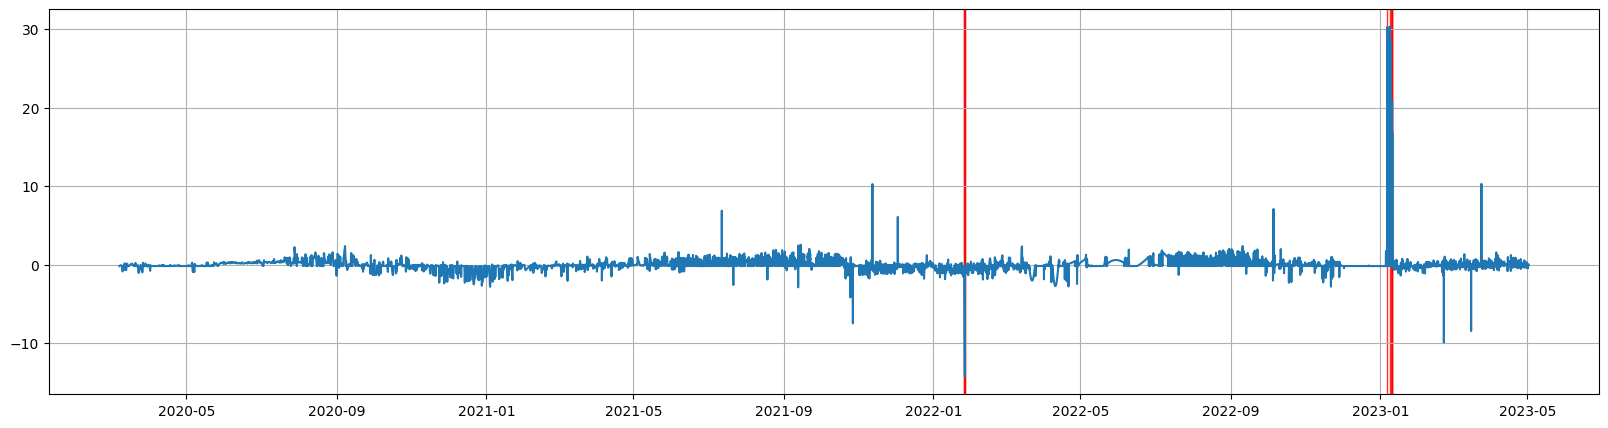

In [97]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(prof1['2020-01-01':'2023-05-01'].index, test)
highlightComaprison(test, pred_outlier_indices, 'red')
plt.grid(True);

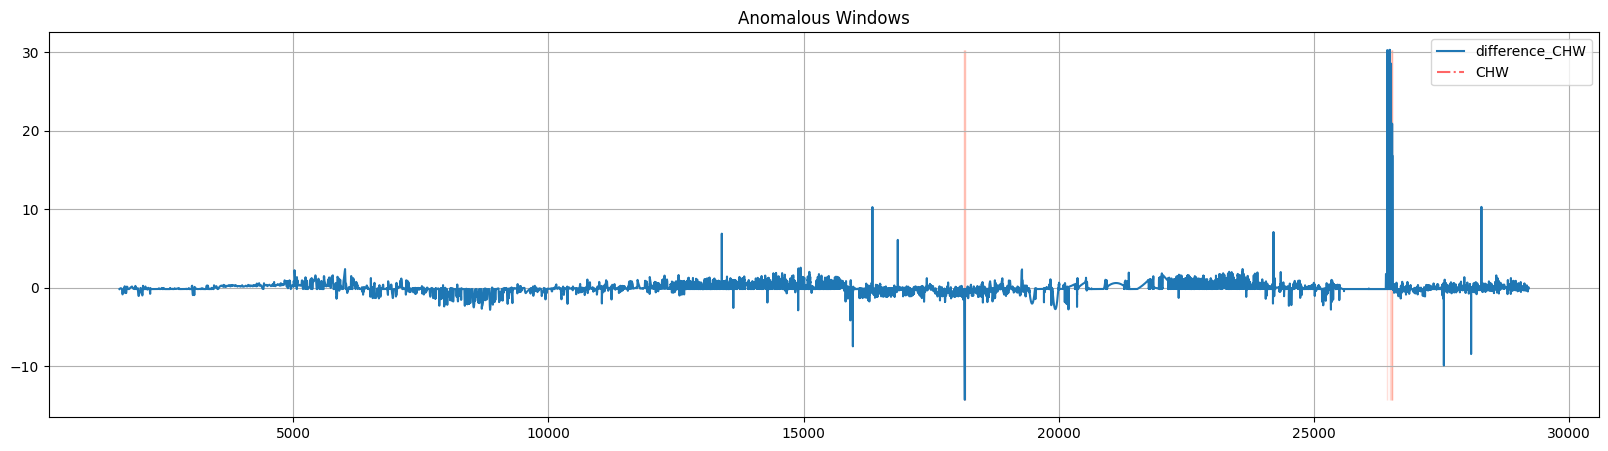

In [98]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(signal_test)
plt.axhline(y=signal_test.mean(), color='r', linestyle='-.', alpha=0.6) # the  horizontal line for mean
plt.axhline(y=signal_test.mean() + signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean + std_dev
plt.axhline(y=signal_test.mean() + 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean + 2 * std_dev
plt.axhline(y=signal_test.mean() - 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean - 2 * std_dev
plt.axhline(y=signal_test.mean() - signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean - std_dev
for w_index in pred_outlier_indices:
    plt.fill_betweenx((np.nanmin(signal_test), np.nanmax(signal_test)), w_index, w_index + intervel_length - 1, alpha=0.2, color='tomato')
plt.title('Anomalous Windows')
plt.legend(["difference_CHW", "CHW"])
plt.grid(True);

In [56]:
### Outlier detection (contain None for spike)

data1 = scaled_df[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]
data1[data1 < -0.1] = None
data1[data1 > 0.1] = None
data1 = data1.fillna(method = "ffill")
data1 = data1.dropna()

# Numerical dataframe
from sklearn.cluster import DBSCAN
model = DBSCAN(eps = 0.001, min_samples = 10).fit(data1)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_62669/3009463891.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data1 = data1.fillna(method = "ffill")


In [35]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2'],
      dtype='object')

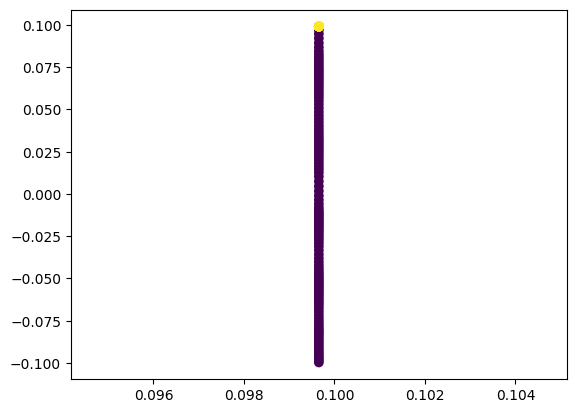

In [38]:
colors = model.labels_
plt.scatter(data1["b084_raw_group2"], data1["b081_raw_group2"], c = colors)

In [39]:
data1[model.labels_ == -1]

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-11-20 19:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.099678
2022-11-20 20:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.098495
2022-11-20 21:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.097326
2022-11-20 22:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.096099
2022-11-20 23:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.094775
...,...,...,...,...,...,...
2022-11-25 13:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.086765
2022-11-25 14:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.089293
2022-11-25 15:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.092072


In [40]:
# GMM 모델 생성
n_clusters = 10  # 클러스터 수를 설정
covariance_type = 'spherical'  # 또는 다른 유형 선택 가능

gmm = GaussianMixture(n_components = n_clusters, covariance_type = covariance_type)
gmm.fit(data1)

# 클러스터 할당
cluster_labels = gmm.predict(data1)

# 결과를 데이터프레임에 추가
data1['Cluster_Label'] = cluster_labels

In [41]:
# Isolation Forest 모델 생성
isolation_forest = IsolationForest(contamination=0.05)  # contamination은 이상치 비율을 나타냅니다

# 모델 훈련
isolation_forest.fit(data1)

# 이상치 여부를 예측 (-1은 이상치, 1은 정상치)
outlier_labels = isolation_forest.predict(data1)

# 결과를 데이터프레임에 추가
data1['Outlier_Label'] = outlier_labels

In [42]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2',
       'Cluster_Label', 'Outlier_Label'],
      dtype='object')

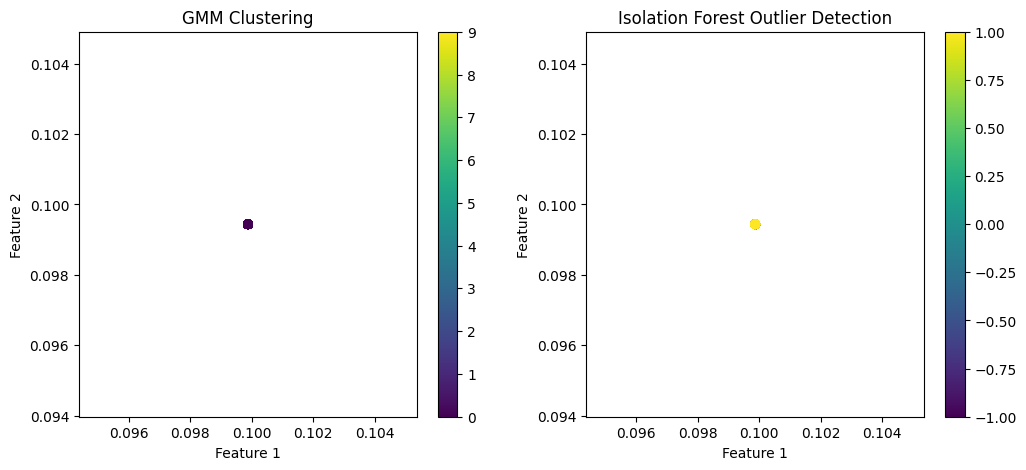

In [44]:
# 클러스터링 결과 및 이상치 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 클러스터링 결과 시각화
scatter1 = ax1.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=cluster_labels, cmap='viridis')
ax1.set_title("GMM Clustering")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
fig.colorbar(scatter1, ax=ax1)

# 이상치 탐지 결과 시각화
scatter2 = ax2.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=outlier_labels, cmap='viridis')
ax2.set_title("Isolation Forest Outlier Detection")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
fig.colorbar(scatter2, ax=ax2)

plt.show()

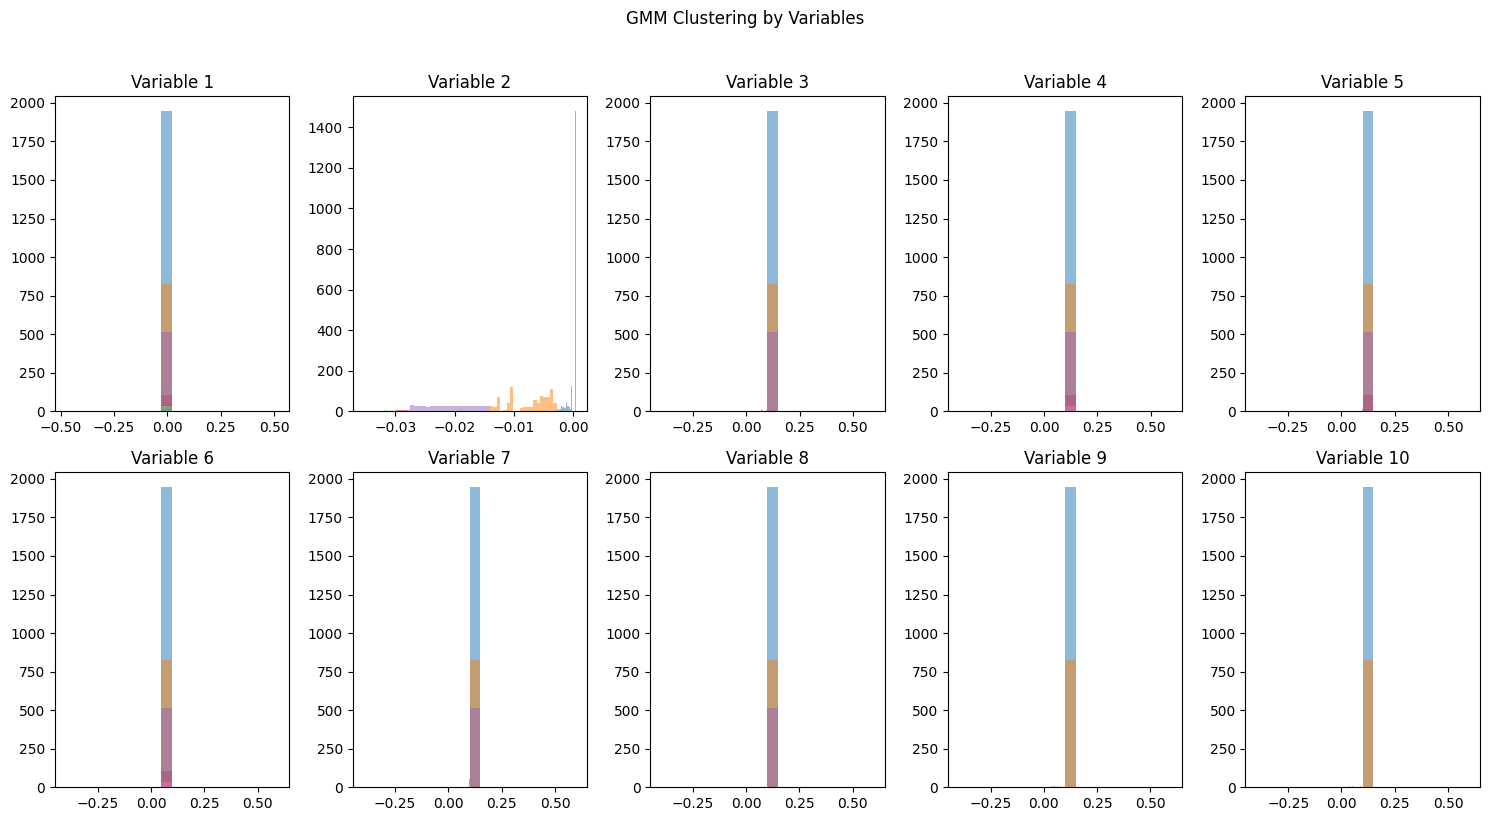

In [103]:
# 클러스터링 결과 시각화
plt.figure(figsize=(15, 8))
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    for i in range(10):  # 10개 변수
        plt.subplot(2, 5, i + 1)
        plt.hist(cluster_data.iloc[:, i], bins = 20, alpha = 0.5, label = f'Cluster {cluster_label + 1}')
        plt.title(f'Variable {i + 1}')
    
plt.suptitle("GMM Clustering by Variables", y = 1.02)
plt.tight_layout()
plt.show()

In [105]:
cluster_data

,b181_raw_group1,b146_raw_group1,b153_raw_group1,b147_raw_group1,b165_raw_group1,b167_raw_group1,b195_raw_group1,b790_raw_group1,b116_raw_group1,b064_raw_group1,Cluster_Label,Outlier_Label
Date/Time,,,,,,,,,,,,
2022-10-11 22:00:00,0.021912,-0.002759,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-11 23:00:00,0.021912,-0.002746,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 00:00:00,0.021912,-0.002732,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 01:00:00,0.021912,-0.002716,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 02:00:00,0.021912,-0.002699,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31 18:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 19:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 20:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1


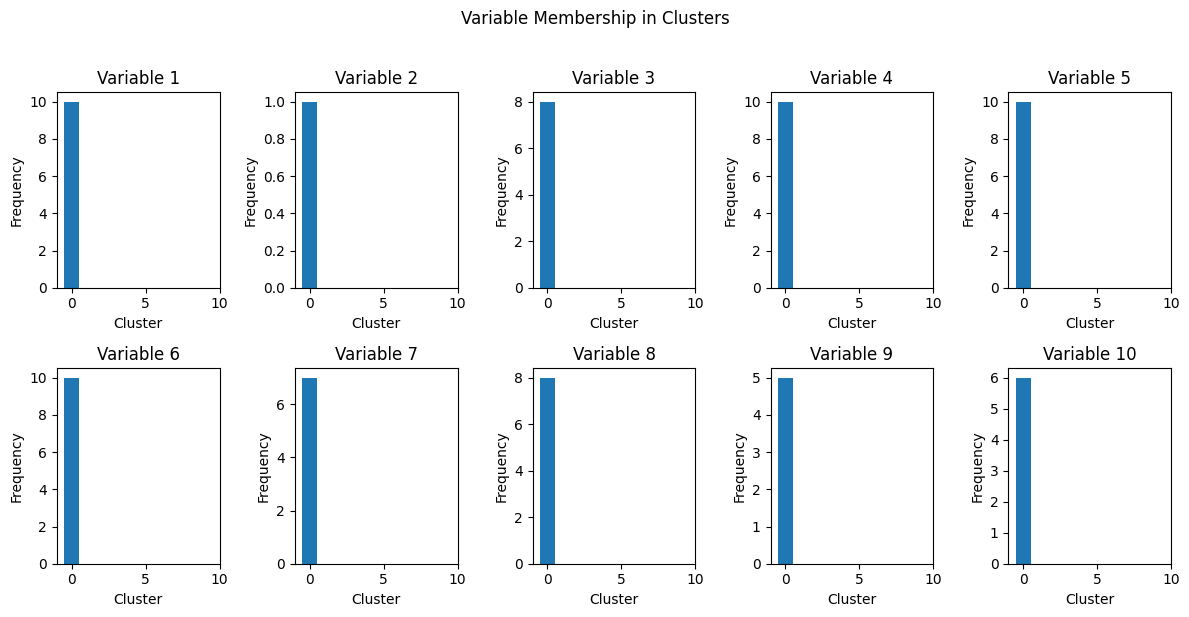

In [107]:
import numpy as np

# 각 변수의 클러스터 소속 확인
variable_cluster_labels = np.zeros((10, n_clusters))  # 변수의 개수 x 클러스터 수
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    cluster_data = cluster_data.drop(['Cluster_Label', "Outlier_Label"], axis = 1)
    variable_cluster_labels[:, cluster_label] = np.mean(cluster_data, axis=0)


# 변수별 클러스터 소속 시각화
plt.figure(figsize=(12, 6))
for i in range(10):  # 10개 변수
    plt.subplot(2, 5, i + 1)
    counts, bins, _ = plt.hist(variable_cluster_labels[i], bins=range(n_clusters + 1), align='left')
    plt.title(f'Variable {i + 1}')
    plt.xlabel('Cluster')
    plt.ylabel('Frequency')
    
plt.suptitle("Variable Membership in Clusters", y=1.02)
plt.tight_layout()
plt.show()


### Generate NAN and Impute GAN (pilot)

In [79]:
data1 = data1.reset_index()
# data1 = data1.drop(['Index'], axis = 1)

In [ ]:
# 결측값 생성

num_points = len(data1)
num_variables = 6
missing_rate = 0.2
for column in df.columns:
    num_missing = int(num_points * missing_rate)
    missing_indices = np.random.choice(num_points, num_missing, replace=False)
    data1.loc[missing_indices, column] = np.nan

In [87]:
data1.index = data1["Date/Time"]
data1 = data1.drop(['Date/Time', "index"], axis = 1)

# Extract data with pt
filtered_columns = [col for col in data1.columns if "raw" in col]

# 선택한 변수를 새로운 데이터 프레임으로 추출
data1 = data1[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]

In [111]:
from tensorflow import keras
import torch
import torch.nn as nn
import torch.optim as optim

In [88]:
data1.head()

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-04-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-01 01:00:00,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2022-04-01 02:00:00,0.0,0.000058,0.000281,NaN,NaN,NaN
2022-04-01 03:00:00,0.0,0.000035,0.000268,0.000308,NaN,NaN
2022-04-01 04:00:00,0.0,NaN,NaN,0.000298,NaN,NaN


In [91]:
data1 = data1.reset_index()
data1 = data1.drop(['Date/Time'], axis = 1)

In [93]:
data1

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2,0.0,0.000058,0.000281,NaN,NaN,NaN
3,0.0,0.000035,0.000268,0.000308,NaN,NaN
4,0.0,NaN,NaN,0.000298,NaN,NaN
...,...,...,...,...,...,...
6594,0.0,0.000035,0.000287,NaN,0.000000,0.000426
6595,0.0,NaN,NaN,0.000286,NaN,NaN
6596,0.0,NaN,0.000265,0.000288,0.000012,0.000416
6597,NaN,NaN,0.000216,NaN,0.000000,0.000435


In [116]:
# 데이터프레임을 PyTorch 텐서로 변환
real_data = torch.FloatTensor(data1.dropna().values)

In [122]:
# Generator 모델 정의
class Generator(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(Generator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, output_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.fc(x)

# Discriminator 모델 정의
class Discriminator(nn.Module):
    def __init__(self, input_dim):
        super(Discriminator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.fc(x)

In [128]:
# Generator와 Discriminator 모델 초기화
input_dim = 32
output_dim = num_variables
generator = Generator(input_dim, output_dim)
discriminator = Discriminator(output_dim)

# 손실 함수 및 옵티마이저 정의
criterion = nn.BCELoss()
optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)

In [134]:
# GAN 모델 훈련
num_epochs = 100
batch_size = 32

for epoch in range(num_epochs):
    num_batches = real_data.shape[0] // batch_size
    for _ in range(num_batches):
        noise = torch.randn(batch_size, input_dim)
        generated_data = generator(noise)
        real_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        fake_labels = torch.zeros((batch_size, 1), dtype=torch.float32)

        # Discriminator 훈련
        optimizer_d.zero_grad()
        real_output = discriminator(real_data[:batch_size])
        fake_output = discriminator(generated_data)
        discriminator_loss_real = criterion(real_output, real_labels)
        discriminator_loss_fake = criterion(fake_output, fake_labels)
        discriminator_loss = discriminator_loss_real + discriminator_loss_fake
        discriminator_loss.backward(retain_graph=True)
        optimizer_d.step()

        # Generator를 통한 GAN 훈련
        optimizer_g.zero_grad()
        gan_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        gan_output = discriminator(generated_data)
        gan_loss = criterion(gan_output, gan_labels)
        gan_loss.backward()
        optimizer_g.step()

    print(f'Epoch {epoch}, D Loss: {discriminator_loss.item()}, G Loss: {gan_loss.item()}')


Epoch 0, D Loss: 1.3854780197143555, G Loss: 0.6327202320098877
Epoch 1, D Loss: 1.3908488750457764, G Loss: 0.6290866136550903
Epoch 2, D Loss: 1.3863091468811035, G Loss: 0.6368914246559143
Epoch 3, D Loss: 1.3897672891616821, G Loss: 0.6354539394378662
Epoch 4, D Loss: 1.3817918300628662, G Loss: 0.6448863744735718
Epoch 5, D Loss: 1.3989853858947754, G Loss: 0.6333292722702026
Epoch 6, D Loss: 1.372666358947754, G Loss: 0.6603043675422668
Epoch 7, D Loss: 1.3731648921966553, G Loss: 0.6610397100448608
Epoch 8, D Loss: 1.3767998218536377, G Loss: 0.6590506434440613
Epoch 9, D Loss: 1.3822531700134277, G Loss: 0.6567761898040771
Epoch 10, D Loss: 1.379887342453003, G Loss: 0.6593412160873413
Epoch 11, D Loss: 1.3736572265625, G Loss: 0.6676796078681946
Epoch 12, D Loss: 1.3731087446212769, G Loss: 0.6703320145606995
Epoch 13, D Loss: 1.3778290748596191, G Loss: 0.6668186783790588
Epoch 14, D Loss: 1.3695826530456543, G Loss: 0.6758610606193542
Epoch 15, D Loss: 1.371976613998413, G L

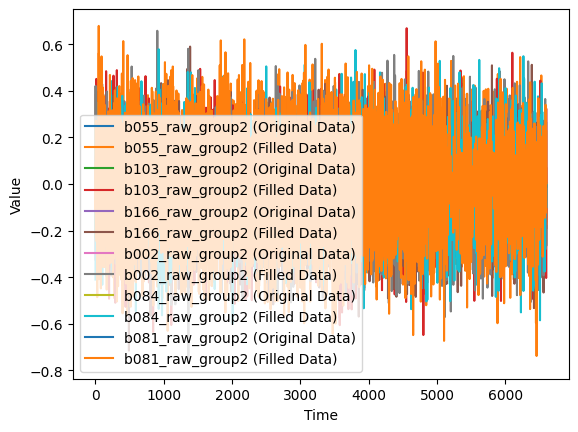

In [136]:
# 결측값을 GAN을 사용하여 채우기
missing_data = data1.copy()
for column in missing_data.columns:
    missing_indices = missing_data[column].isna()
    num_missing = missing_indices.sum()
    noise = torch.randn(num_missing, input_dim)
    generated_values = generator(noise).detach().numpy()
    missing_data.loc[missing_indices, column] = generated_values.flatten()[:num_missing]

# 결과를 시각화
for column in data1.columns:
    plt.plot(data1[column], label=f'{column} (Original Data)')
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

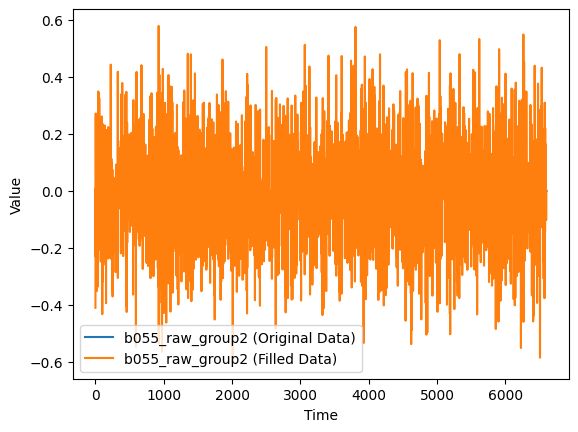

In [148]:
# 결과를 시각화

plt.plot(data1["b084_raw_group2"], label=f'{column} (Original Data)')
plt.plot(missing_data["b084_raw_group2"], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

ValueError: x and y must be the same size

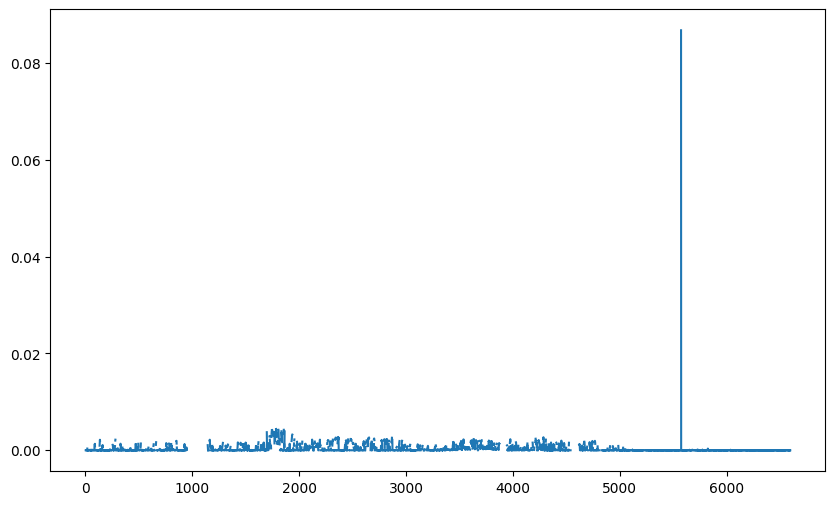

In [141]:
# 결과를 시각화
for column in data1.columns:
    plt.figure(figsize=(10, 6))
    plt.plot(data1[column], label=f'{column} (Original Data)')
    
    # 결측값인 지점에 동그라미 표시
    missing_indices = data1[column].isna()
    plt.scatter(missing_indices.index, data1[column][missing_indices], c='r', marker='o', label='Missing Data')
    
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
    
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()